<a href="https://colab.research.google.com/github/Jayatheerthan24/SAT2_DS/blob/main/DSSAT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import zipfile
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Extract zip file
zip_path = '/content/freshcart_supermarket_sales_synthetic.zip'
extract_dir = '/content/freshcart_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("Extracted files:", os.listdir(extract_dir))

Extracted files: ['sales.csv', 'README.txt', 'stores.csv', 'calendar.csv', 'products.csv', 'promotions.csv']


In [2]:
sales_df = pd.read_csv(os.path.join(extract_dir, 'sales.csv'))
products_df = pd.read_csv(os.path.join(extract_dir, 'products.csv'))
stores_df = pd.read_csv(os.path.join(extract_dir, 'stores.csv'))
promotions_df = pd.read_csv(os.path.join(extract_dir, 'promotions.csv'))
calendar_df = pd.read_csv(os.path.join(extract_dir, 'calendar.csv'))

# Store initial shapes
initial_shapes = {
    'sales': sales_df.shape,
    'products': products_df.shape,
    'stores': stores_df.shape,
    'promotions': promotions_df.shape,
    'calendar': calendar_df.shape
}

for name, df in [('Sales', sales_df), ('Products', products_df), ('Stores', stores_df), ('Promotions', promotions_df), ('Calendar', calendar_df)]:
    print(f"=== {name} Dataset ===")
    print(f"Shape: {df.shape}")
    print(f"Columns: {list(df.columns)}")
    print(f"Missing values:\n{df.isnull().sum()}")
    print(f"Duplicates: {df.duplicated().sum()}\n")

=== Sales Dataset ===
Shape: (10080, 7)
Columns: ['sale_id', 'date', 'store_id', 'product_id', 'promotion_id', 'units', 'revenue']
Missing values:
sale_id           0
date             25
store_id          0
product_id        0
promotion_id    151
units             0
revenue          10
dtype: int64
Duplicates: 80

=== Products Dataset ===
Shape: (120, 7)
Columns: ['product_id', 'product_name', 'category', 'brand', 'price_band', 'list_price', 'unit_cost']
Missing values:
product_id      0
product_name    0
category        0
brand           0
price_band      0
list_price      0
unit_cost       0
dtype: int64
Duplicates: 0

=== Stores Dataset ===
Shape: (15, 6)
Columns: ['store_id', 'store_name', 'city', 'store_format', 'floor_area_sqft', 'store_open_date']
Missing values:
store_id           0
store_name         0
city               0
store_format       0
floor_area_sqft    0
store_open_date    0
dtype: int64
Duplicates: 0

=== Promotions Dataset ===
Shape: (8, 5)
Columns: ['promotion_id'

In [15]:
# Clean Products
products_df['category'] = products_df['category'].str.strip().str.title()

# Clean Sales
# Remove duplicate records
sales_cleaned = sales_df.drop_duplicates().copy()

# Drop rows where date is missing (essential for time alignment)
sales_cleaned = sales_cleaned.dropna(subset=['date'])

# Filter out invalid values
sales_cleaned = sales_cleaned[sales_cleaned['units'] > 0]
sales_cleaned = sales_cleaned[sales_cleaned['revenue'] >= 0]

# Handle missing promotion_id with a default code ('No Promo' / PR00)
sales_cleaned['promotion_id'] = sales_cleaned['promotion_id'].fillna('PR00')

# Convert date fields to standard datetime format
sales_cleaned['date'] = pd.to_datetime(sales_cleaned['date'])
calendar_df['date'] = pd.to_datetime(calendar_df['date'])

# Handle missing flags in Calendar
calendar_df['is_holiday'] = calendar_df['is_holiday'].fillna(0).astype(int)

# Create 'is_festival' as a binary indicator from the 'festival' column
calendar_df['is_festival'] = calendar_df['festival'].notna().astype(int)
calendar_df['festival'] = calendar_df['festival'].fillna('No Festival')

# Merge datasets using appropriate keys
merged_df = sales_cleaned.merge(products_df, on='product_id', how='inner')
merged_df = merged_df.merge(stores_df, on='store_id', how='inner')
merged_df = merged_df.merge(calendar_df, on='date', how='inner')
merged_df = merged_df.merge(promotions_df, on='promotion_id', how='left')

# Save the final cleaned analysis dataset
merged_df.to_csv('/content/cleaned_sales.csv', index=False)
print(f"Original Sales Rows: {sales_df.shape[0]}")
print(f"Cleaned & Merged Sales Rows: {merged_df.shape[0]}")

Original Sales Rows: 10080
Cleaned & Merged Sales Rows: 9920


/tmp/ipykernel_1210/2466644201.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='revenue', y='category', data=rev_by_cat, palette='viridis')


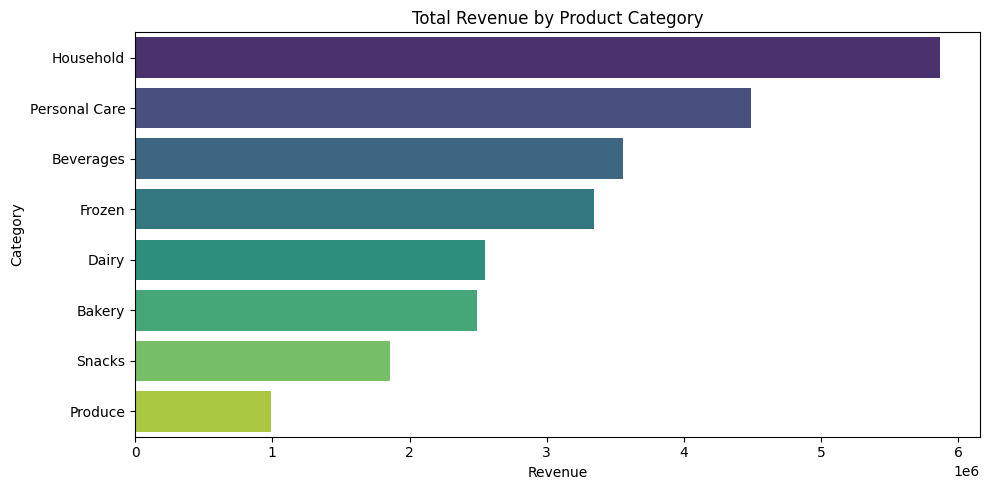

In [16]:
# 1. Revenue by Category
rev_by_cat = merged_df.groupby('category')['revenue'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(x='revenue', y='category', data=rev_by_cat, palette='viridis')
plt.title('Total Revenue by Product Category')
plt.xlabel('Revenue')
plt.ylabel('Category')
plt.tight_layout()
plt.savefig('/content/revenue_by_category.png')
plt.show()

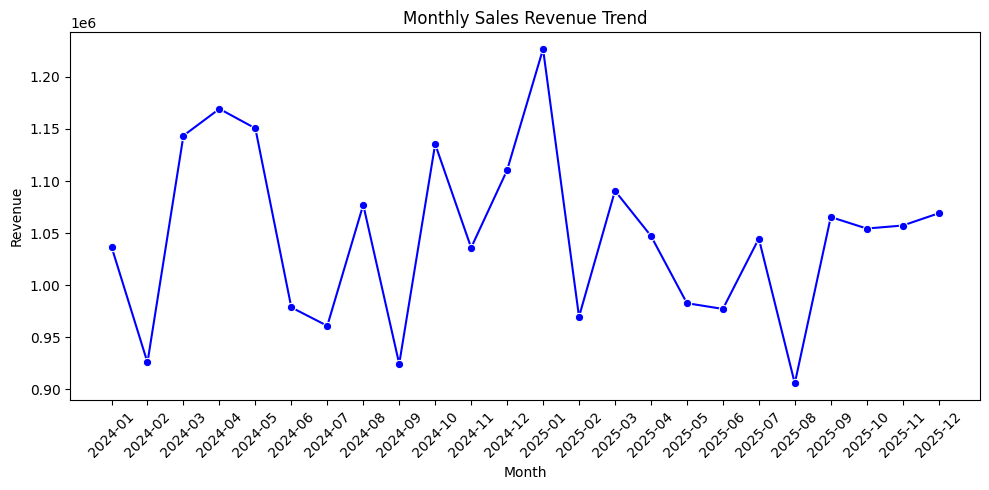

In [17]:
# 2. Monthly sales trend
merged_df['month_yr'] = merged_df['date'].dt.to_period('M')
monthly_sales = merged_df.groupby('month_yr')['revenue'].sum().reset_index()
monthly_sales['month_yr'] = monthly_sales['month_yr'].astype(str)

plt.figure(figsize=(10, 5))
sns.lineplot(x='month_yr', y='revenue', data=monthly_sales, marker='o', color='b')
plt.title('Monthly Sales Revenue Trend')
plt.xticks(rotation=45)
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.tight_layout()
plt.savefig('/content/monthly_sales_trend.png')
plt.show()

/tmp/ipykernel_1210/2207340567.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='units', y='campaign', data=promo_sales, palette='magma')


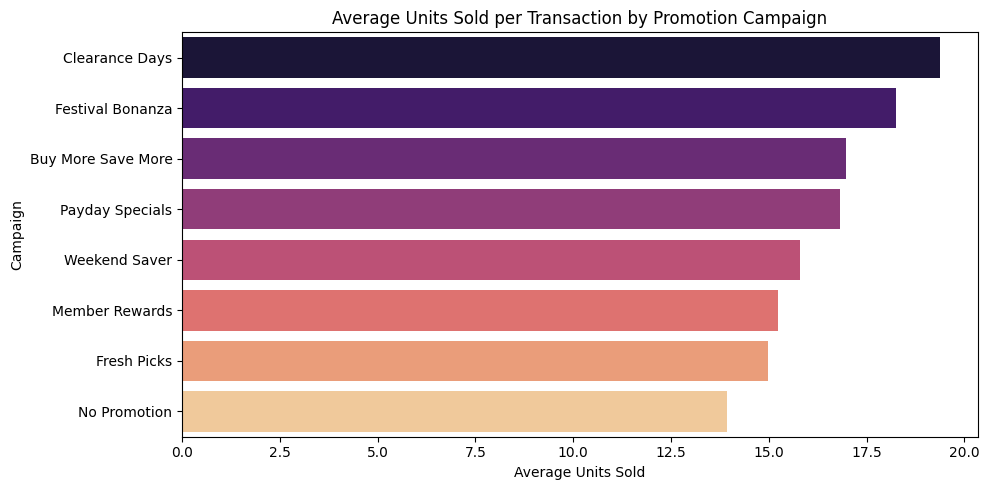

In [18]:
# 3. Promotion Performance
promo_sales = merged_df.groupby('campaign')['units'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(x='units', y='campaign', data=promo_sales, palette='magma')
plt.title('Average Units Sold per Transaction by Promotion Campaign')
plt.xlabel('Average Units Sold')
plt.ylabel('Campaign')
plt.tight_layout()
plt.savefig('/content/promotion_comparison.png')
plt.show()

/tmp/ipykernel_1210/1277099844.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='is_festival', y='units', data=fest_sales, palette='coolwarm')


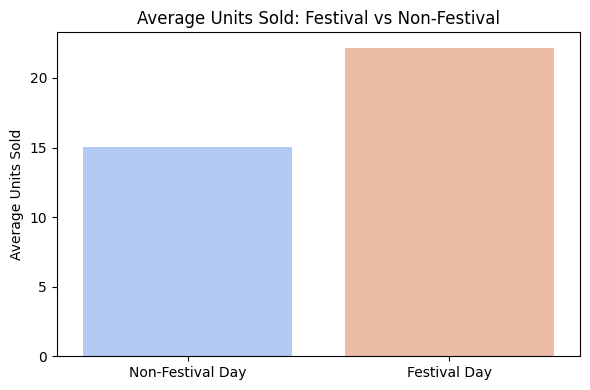

In [19]:
# 4. Festival vs Non-Festival Demand
fest_sales = merged_df.groupby('is_festival')['units'].mean().reset_index()
fest_sales['is_festival'] = fest_sales['is_festival'].map({0: 'Non-Festival Day', 1: 'Festival Day'})

plt.figure(figsize=(6, 4))
sns.barplot(x='is_festival', y='units', data=fest_sales, palette='coolwarm')
plt.title('Average Units Sold: Festival vs Non-Festival')
plt.xlabel('')
plt.ylabel('Average Units Sold')
plt.tight_layout()
plt.savefig('/content/festival_vs_nonfestival.png')
plt.show()

In [22]:
# Aggregate transaction records to store-product-day level
agg_df = merged_df.groupby(['store_id', 'product_id', 'date', 'category', 'brand', 'store_format', 'city', 'floor_area_sqft', 'is_holiday', 'is_festival']).agg(
    units=('units', 'sum'),
    avg_price=('revenue', lambda x: (x / merged_df.loc[x.index, 'units']).mean() if merged_df.loc[x.index, 'units'].sum() > 0 else 0)
).reset_index()

# Feature Engineering
agg_df['month'] = agg_df['date'].dt.month
agg_df['day_of_week'] = agg_df['date'].dt.dayofweek
agg_df['is_weekend'] = agg_df['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)

# Select target and model features
features = ['category', 'brand', 'store_format', 'city', 'floor_area_sqft', 'is_holiday', 'is_festival', 'month', 'day_of_week', 'is_weekend', 'avg_price']
target = 'units'

X = agg_df[features].copy()
y = agg_df[target].copy()

# One-Hot Encoding for categorical features
X_encoded = pd.get_dummies(X, drop_first=True)

# Chronological Train-Test Split (last 20% of dates as holdout)
unique_dates = sorted(agg_df['date'].unique())
split_idx = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_idx]

train_mask = agg_df['date'] < split_date
test_mask = agg_df['date'] >= split_date

X_train, X_test = X_encoded[train_mask], X_encoded[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

print(f"Train set shape: {X_train.shape}, Test set shape: {X_test.shape}")

Train set shape: (7949, 29), Test set shape: (1932, 29)


In [25]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Baseline Model (Mean of Train Target)
y_pred_baseline = np.full_like(y_test, fill_value=y_train.mean())

# 2. HistGradientBoostingRegressor
hgbr = HistGradientBoostingRegressor(max_iter=100, random_state=42)
hgbr.fit(X_train, y_train)
y_pred_hgbr = hgbr.predict(X_test)

# 3. Random Forest
rf = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# Evaluate Models
def get_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

metrics_data = {
    'Model': ['Baseline', 'HistGradientBoosting', 'Random Forest'],
    'MAE': [get_metrics(y_test, y_pred_baseline)[0], get_metrics(y_test, y_pred_hgbr)[0], get_metrics(y_test, y_pred_rf)[0]],
    'RMSE': [get_metrics(y_test, y_pred_baseline)[1], get_metrics(y_test, y_pred_hgbr)[1], get_metrics(y_test, y_pred_rf)[1]],
    'R2': [get_metrics(y_test, y_pred_baseline)[2], get_metrics(y_test, y_pred_hgbr)[2], get_metrics(y_test, y_pred_rf)[2]]
}

metrics_df = pd.DataFrame(metrics_data)
display(metrics_df)
metrics_df.to_csv('/content/model_metrics.csv', index=False)

,Model,MAE,RMSE,R2
0,Baseline,7.049172,8.735503,-0.000239
1,HistGradientBoosting,3.875462,5.113488,0.657262
2,Random Forest,5.039932,6.461180,0.452793


/tmp/ipykernel_1210/679214142.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=feat_imp_df.head(10), palette='plasma')


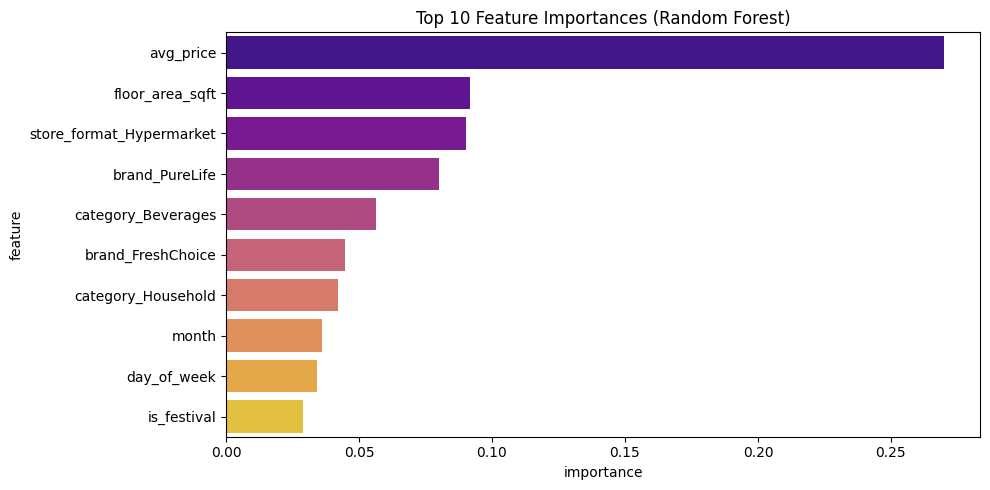

In [24]:
# Save predictions
predictions_df = pd.DataFrame({
    'actual_units': y_test,
    'predicted_units': y_pred_hgbr
})
predictions_df.to_csv('/content/predictions.csv', index=False)

# Feature Importances from Random Forest
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

feat_imp_df = pd.DataFrame({
    'feature': X_train.columns[indices],
    'importance': importances[indices]
})
feat_imp_df.to_csv('/content/feature_importance.csv', index=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='importance', y='feature', data=feat_imp_df.head(10), palette='plasma')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.tight_layout()
plt.savefig('/content/feature_importance.png')
plt.show()

In [28]:
import pandas as pd

# Load cleaned sales dataset directly to avoid scope issues
merged_df_clean = pd.read_csv('/content/cleaned_sales.csv')

# Compute KPI cards
total_rev = merged_df_clean['revenue'].sum()
total_units = merged_df_clean['units'].sum()
num_stores = merged_df_clean['store_id'].nunique()
top_cat = merged_df_clean.groupby('category')['revenue'].sum().idxmax()

print(f"--- KPIs ---")
print(f"Total Revenue: ${total_rev:,.2f}")
print(f"Total Units Sold: {total_units:,}")
print(f"Number of Stores: {num_stores}")
print(f"Top-performing Product Category: {top_cat}")

--- KPIs ---
Total Revenue: $25,140,779.06
Total Units Sold: 150,291
Number of Stores: 15
Top-performing Product Category: Household


In [33]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd

# Ensure date column is parsed as datetime to extract month_yr
merged_df_clean['date'] = pd.to_datetime(merged_df_clean['date'])
merged_df_clean['month_yr'] = merged_df_clean['date'].dt.to_period('M').astype(str)

# Prepare dynamic dashboard data
category_rev = merged_df_clean.groupby('category')['revenue'].sum().reset_index()
monthly_rev = merged_df_clean.groupby('month_yr')['revenue'].sum().reset_index()

# Create subplots for the interactive dashboard
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=("Revenue by Category", "Monthly Sales Revenue Trend", "Units Sold by Campaign", "Festival vs Non-Festival Demand"),
    vertical_spacing=0.15
)

# Add Category Trace
fig.add_trace(
    go.Bar(x=category_rev['category'], y=category_rev['revenue'], name='Revenue', marker_color='teal'),
    row=1, col=1
)

# Add Monthly Trace
fig.add_trace(
    go.Scatter(x=monthly_rev['month_yr'], y=monthly_rev['revenue'], mode='lines+markers', name='Monthly Trend', line=dict(color='blue')),
    row=1, col=2
)

# Add Promo Trace
fig.add_trace(
    go.Bar(x=promo_sales['campaign'], y=promo_sales['units'], name='Promo Sales', marker_color='indigo'),
    row=2, col=1
)

# Add Festival Trace
fig.add_trace(
    go.Bar(x=fest_sales['is_festival'], y=fest_sales['units'], name='Festival Avg', marker_color='crimson'),
    row=2, col=2
)

fig.update_layout(height=800, width=1000, title_text="FreshCart Store Performance & Intelligence Dashboard (Prototype)", showlegend=False)
fig.show()